Import Libery

In [ ]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, confusion_matrix,classification_report, roc_curve, auc

import tensorflow as tf
from tensorflow.keras.applications.vgg19 import VGG19
from tensorflow.keras.layers import Dense, Flatten, Dropout, LeakyReLU, Conv2D, Activation,GlobalAveragePooling2D,Input,  MaxPooling2D, concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import plot_model
import numpy as np
import matplotlib.pyplot as plt
import zipfile




# ** Mount Google Drive**

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Set the paths to the dataset zip file and the directories for training and validation data
dataset_zip_path = '/content/drive/MyDrive/grape.zip'


In [ ]:
# Extract the dataset zip file
with zipfile.ZipFile(dataset_zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content')

4 class

In [ ]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

# Define the directory containing the original dataset
original_dataset_dir = '/content/Grape'
# Define the directory to save the augmented images
augmented_dataset_dir = '/content/augmented_dataset1'

# Ensure the augmented dataset directory exists
os.makedirs(augmented_dataset_dir, exist_ok=True)

# Define the augmentation parameters
datagen = ImageDataGenerator(
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest')

# Loop through each class subfolder
for class_name in os.listdir(original_dataset_dir):
    class_dir = os.path.join(original_dataset_dir, class_name)
    augmented_class_dir = os.path.join(augmented_dataset_dir, class_name)
    os.makedirs(augmented_class_dir, exist_ok=True)

    # Loop through each image in the class subfolder
    for img_name in os.listdir(class_dir):
        img_path = os.path.join(class_dir, img_name)

        # Load the image and reshape it to fit the flow method
        img = load_img(img_path)
        x = img_to_array(img)
        x = x.reshape((1,) + x.shape)

        # Generate augmented images and save them
        i = 0
        for batch in datagen.flow(x, batch_size=1, save_to_dir=augmented_class_dir, save_prefix='aug', save_format='jpeg'):
            i += 1
            if i >= 4:  # Generate 4 augmented images for each original image
                break  # Break the loop to prevent infinite loop

    # Count the total number of images in the augmented class directory
    num_augmented_images = len(os.listdir(augmented_class_dir))

    # Calculate the number of images to reach 5000
    num_images_to_generate = max(0, 5 - num_augmented_images)

    # Generate additional augmented images if needed
    i = 0
    for img_name in os.listdir(class_dir):
        img_path = os.path.join(class_dir, img_name)
        img = load_img(img_path)
        x = img_to_array(img)
        x = x.reshape((1,) + x.shape)

        for batch in datagen.flow(x, batch_size=1, save_to_dir=augmented_class_dir, save_prefix='aug', save_format='jpeg'):
            i += 1
            if i >= num_images_to_generate:
                break  # Break the loop once the required number of images are generated

print("Augmentation completed.")

Augmentation completed.


For 2 class

In [ ]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

# Define the directory containing the original dataset
original_dataset_dir = '/content/Bell pepper/train'
# Define the directory to save the augmented images
augmented_dataset_dir = '/content/augmented_dataset'

# Ensure the augmented dataset directory exists
os.makedirs(augmented_dataset_dir, exist_ok=True)

# Define the augmentation parameters
datagen = ImageDataGenerator(
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest')

# Loop through each class subfolder
subfolders = os.listdir(original_dataset_dir)
for class_name in subfolders[:2]:  # Considering only the first 2 subfolders
    class_dir = os.path.join(original_dataset_dir, class_name)
    augmented_class_dir = os.path.join(augmented_dataset_dir, class_name)
    os.makedirs(augmented_class_dir, exist_ok=True)

    # Loop through each image in the class subfolder
    for img_name in os.listdir(class_dir):
        img_path = os.path.join(class_dir, img_name)

        try:
            # Load the image and reshape it to fit the flow method
            img = load_img(img_path)
            x = img_to_array(img)
            x = x.reshape((1,) + x.shape)

            # Generate augmented images and save them
            i = 0
            for batch in datagen.flow(x, batch_size=1, save_to_dir=augmented_class_dir, save_prefix='aug', save_format='jpeg'):
                i += 1
                if i >= 4:  # Generate 4 augmented images for each original image
                    break  # Break the loop to prevent infinite loop

        except Exception as e:
            print(f"Error processing image {img_path}: {e}")

    # Count the total number of images in the augmented class directory
    num_augmented_images = len(os.listdir(augmented_class_dir))

    # Calculate the number of images to reach 5000
    num_images_to_generate = max(0, 5 - num_augmented_images)

    # Generate additional augmented images if needed
    i = 0
    for img_name in os.listdir(class_dir):
        img_path = os.path.join(class_dir, img_name)

        try:
            img = load_img(img_path)
            x = img_to_array(img)
            x = x.reshape((1,) + x.shape)

            for batch in datagen.flow(x, batch_size=1, save_to_dir=augmented_class_dir, save_prefix='aug', save_format='jpeg'):
                i += 1
                if i >= num_images_to_generate:
                    break  # Break the loop once the required number of images are generated

        except Exception as e:
            print(f"Error processing image {img_path}: {e}")

print("Augmentation completed.")


Error processing image /content/Bell pepper/train/Bell pepper Bacterial spot/classes.txt: cannot identify image file <_io.BytesIO object at 0x7e22b09e8a40>
Error processing image /content/Bell pepper/train/Bell pepper Bacterial spot/classes.txt: cannot identify image file <_io.BytesIO object at 0x7e22af44bfb0>
Augmentation completed.


Splitting code

In [ ]:
import os
import random
import shutil

# Set the path to the folder containing the dataset
#dataset_path = "/content/augmented_dataset1"

dataset_path = "/content/grape"
# Set the path to the folder where the split datasets will be saved
output_path = "/content/dataset2"


# Set the percentage of data to use for training, validation, and testing
train_ratio = 0.7
valid_ratio = 0.20
test_ratio = 0.10

# Create the output folders
train_path = os.path.join(output_path, "train")
valid_path = os.path.join(output_path, "valid")
test_path = os.path.join(output_path, "test")
os.makedirs(train_path, exist_ok=True)
os.makedirs(valid_path, exist_ok=True)
os.makedirs(test_path, exist_ok=True)

# Iterate over the folders in the dataset
for folder in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder)
    if os.path.isdir(folder_path):
        # Create the corresponding subfolders in the output folders
        train_folder_path = os.path.join(train_path, folder)
        valid_folder_path = os.path.join(valid_path, folder)
        test_folder_path = os.path.join(test_path, folder)
        os.makedirs(train_folder_path, exist_ok=True)
        os.makedirs(valid_folder_path, exist_ok=True)
        os.makedirs(test_folder_path, exist_ok=True)

        # Get the list of image files in the folder
        image_files = os.listdir(folder_path)

        # Shuffle the image files randomly
        random.shuffle(image_files)

        # Split the image files into training, validation, and test sets
        num_files = len(image_files)
        num_train = int(num_files * train_ratio)
        num_valid = int(num_files * valid_ratio)
        num_test = num_files - num_train - num_valid

        train_files = image_files[:num_train]
        valid_files = image_files[num_train:num_train + num_valid]
        test_files = image_files[num_train + num_valid:]

        # Move the image files to the corresponding split folders
        for filename in train_files:
            src = os.path.join(folder_path, filename)
            dst = os.path.join(train_folder_path, filename)
            shutil.copy(src, dst)

        for filename in valid_files:
            src = os.path.join(folder_path, filename)
            dst = os.path.join(valid_folder_path, filename)
            shutil.copy(src, dst)

        for filename in test_files:
            src = os.path.join(folder_path, filename)
            dst = os.path.join(test_folder_path, filename)
            shutil.copy(src, dst)

print("Dataset split successfully!")


Dataset split successfully!


In [ ]:
# Define the hyperparameters
num_classes = 4
batch_size = 9
num_epochs = 70

input_shape=(256, 256, 3)

In [ ]:
train_dir = '/content/dataset2/train'
val_dir = '/content/dataset2/valid'
test_dir = '/content/dataset2/test'


In [ ]:
# Create data generators for training and validation
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=input_shape[:2],
    batch_size=batch_size,
    class_mode='categorical',
shuffle=True
)
val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=input_shape[:2],
    batch_size=batch_size,
    class_mode='categorical',
shuffle=True
)
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=input_shape[:2],
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False

)


Found 2273 images belonging to 4 classes.
Found 648 images belonging to 4 classes.
Found 330 images belonging to 4 classes.


In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, DepthwiseConv2D, Dropout, MaxPooling2D, AveragePooling2D, BatchNormalization, Input, Flatten, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.activations import gelu
from tensorflow.keras.layers import MultiHeadAttention, LayerNormalization, Activation

class ModifiedAdamax(tf.keras.optimizers.Adamax):
    def _resource_apply_dense(self, grad, var, apply_state=None):
        lr_t = self._decayed_lr(tf.float32)  # Modified learning rate
        m = self.get_slot(var, "m")
        v = self.get_slot(var, "v")
        vhat = self.get_slot(var, "vhat")

        m_t = m.assign(m * self._beta_1 + grad * (1. - self._beta_1))
        v_t = tf.maximum(v * self._beta_2, tf.abs(grad))
        vhat_t = vhat.assign(vhat * self._beta_2 + v_t * (1. - self._beta_2))

        var_t = var.assign_sub(lr_t * (m_t / (vhat_t + self.epsilon)))  # Modified update equation

        return tf.group(*[var_t, m_t, v_t, vhat_t])

def ensemble_activation(x):
    alpha = 0.3  # Adjust the alpha value as needed
    gelu_output = gelu(x)
    leaky_relu_output = tf.nn.leaky_relu(x, alpha)
    return (gelu_output + leaky_relu_output) / 2

def depthwise_separable_conv(inputs, filters):
    x = DepthwiseConv2D(3, padding='same')(inputs)
    x = Conv2D(filters, 1, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation(ensemble_activation)(x)  # Using ensemble activation
    return x

def VGG19_Simplified(input_shape=(256, 256, 3), num_classes=2):
    inputs = Input(shape=input_shape)

    # Block 1
    x = depthwise_separable_conv(inputs, 32)
    x = depthwise_separable_conv(x, 32)
    x = BatchNormalization(renorm=True)(x)
    x = MaxPooling2D(2, strides=2, padding='same')(x)

    # Block 2
    x = depthwise_separable_conv(x, 64)
    x = depthwise_separable_conv(x, 64)
    x = BatchNormalization(renorm=True)(x)
    x = MaxPooling2D(2, strides=2, padding='same')(x)

    # Block 3
    x = depthwise_separable_conv(x, 128)
    x = depthwise_separable_conv(x, 128)
    x = BatchNormalization(renorm=True)(x)
    x = MaxPooling2D(2, strides=2, padding='same')(x)

    # Convolutional layer before Capsule Layer
    x = Conv2D(32, 1, strides=1, padding='same')(x)

    # Classification block
    x = AveragePooling2D(7)(x)
    x = Flatten()(x)
    x = Dense(512, activation=ensemble_activation, kernel_regularizer=l2(0.0001))(x)
    x = Dropout(0.5)(x)
    x = Dense(256, activation=ensemble_activation, kernel_regularizer=l2(0.00001))(x)
    x = Dropout(0.3)(x)

    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs)
    return model

# Create the modified Adamax optimizer
optimizer = ModifiedAdamax(learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-10)

# Compile the model with the modified optimizer
model = VGG19_Simplified(input_shape=(256, 256, 3), num_classes=2)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

# Print the model summary
model.summary()

In [ ]:
import numpy as np

# Calculate the number of parameters in the model
total_parameters = np.sum([np.prod(param.shape) for param in model.trainable_variables])

# Assuming each parameter is stored using 32-bit float
size_per_parameter = 4  # 32 bits / 8 bits/byte = 4 bytes

# Calculate the model size in MB
model_size_mb = (total_parameters * size_per_parameter) / (1024 ** 2)  # Convert bytes to MB

print(f"Approximate model size: {model_size_mb:.2f} MB")


Approximate model size: 73.97 MB


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
# Define the paths to save the best weights
best_weights_path = 'best_weight.h5'

# Define the EarlyStopping and ModelCheckpoint callbacks
early_stop = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)
model_checkpoint = ModelCheckpoint(best_weights_path, monitor='accuracy', save_best_only=True)

In [ ]:

# Train the model
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    validation_data=val_generator,
    validation_steps=val_generator.samples // batch_size,
    epochs=num_epochs,
    shuffle=True,
    callbacks=model_checkpoint                #early_stop ]
)

Epoch 1/70


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


252/252 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step - accuracy: 0.6402 - loss: 1.1430

252/252 ━━━━━━━━━━━━━━━━━━━━ 108s 268ms/step - accuracy: 0.6405 - loss: 1.1417 - val_accuracy: 0.1034 - val_loss: 1.6483
Epoch 2/70
  1/252 ━━━━━━━━━━━━━━━━━━━━ 43s 173ms/step - accuracy: 0.7778 - loss: 0.5868

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


252/252 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.7778 - loss: 0.5868 - val_accuracy: 0.1034 - val_loss: 1.6467
Epoch 3/70
252/252 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.8197 - loss: 0.5720

252/252 ━━━━━━━━━━━━━━━━━━━━ 46s 184ms/step - accuracy: 0.8197 - loss: 0.5720 - val_accuracy: 0.1034 - val_loss: 2.0742
Epoch 4/70
  1/252 ━━━━━━━━━━━━━━━━━━━━ 44s 177ms/step - accuracy: 0.8889 - loss: 0.2798

252/252 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8889 - loss: 0.2798 - val_accuracy: 0.1034 - val_loss: 1.9768
Epoch 5/70
252/252 ━━━━━━━━━━━━━━━━━━━━ 76s 174ms/step - accuracy: 0.8609 - loss: 0.4646 - val_accuracy: 0.2994 - val_loss: 5.1127
Epoch 6/70
252/252 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7778 - loss: 0.7608 - val_accuracy: 0.2793 - val_loss: 4.9927
Epoch 7/70
252/252 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.8830 - loss: 0.3818

252/252 ━━━━━━━━━━━━━━━━━━━━ 43s 169ms/step - accuracy: 0.8830 - loss: 0.3817 - val_accuracy: 0.7917 - val_loss: 0.6939
Epoch 8/70
  1/252 ━━━━━━━━━━━━━━━━━━━━ 37s 148ms/step - accuracy: 1.0000 - loss: 0.1601

252/252 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 1.0000 - loss: 0.1601 - val_accuracy: 0.7654 - val_loss: 0.8136
Epoch 9/70
252/252 ━━━━━━━━━━━━━━━━━━━━ 43s 171ms/step - accuracy: 0.8904 - loss: 0.3561 - val_accuracy: 0.7978 - val_loss: 0.8172
Epoch 10/70
252/252 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 1.0000 - loss: 0.0949 - val_accuracy: 0.7994 - val_loss: 0.7736
Epoch 11/70
252/252 ━━━━━━━━━━━━━━━━━━━━ 80s 175ms/step - accuracy: 0.9125 - loss: 0.3087 - val_accuracy: 0.9321 - val_loss: 0.2498
Epoch 12/70
252/252 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 1.0000 - loss: 0.0901 - val_accuracy: 0.9306 - val_loss: 0.2535
Epoch 13/70
252/252 ━━━━━━━━━━━━━━━━━━━━ 78s 173ms/step - accuracy: 0.9213 - loss: 0.2676 - val_accuracy: 0.9151 - val_loss: 0.3382
Epoch 14/70
252/252 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 1.0000 - loss: 0.0627 - val_accuracy: 0.9120 - val_loss: 0.3670
Epoch 15/70
252/252 ━━━━━━━━━━━━━━━━━━━━ 79s 173ms/step - accuracy: 0.9530 - loss: 0.2218 - val_a

In [ ]:
# Load the best weights from the saved file
model.load_weights(best_weights_path)


# ***Training and validation evaluation ***

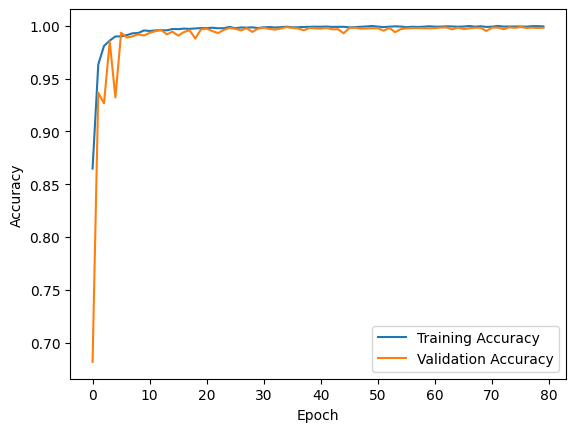

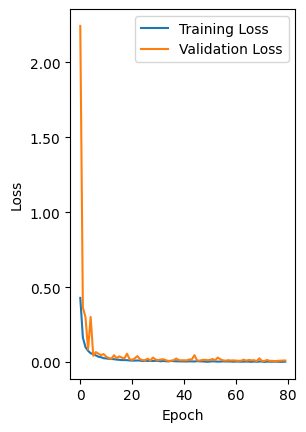

In [ ]:

# Plot the training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
# Set the y-axis tick format to two decimal places
plt.gca().yaxis.set_major_formatter('{:.2f}'.format)

plt.show()

# ***EVALUVATION OF BINARY***

Found 13161 images belonging to 2 classes.
Found 3760 images belonging to 2 classes.
418/418 [==============================] - 14s 34ms/step
Training Accuracy: 0.994757237291999
Validation Accuracy: 0.9922872340425531
Training Precision: 0.9900119260584377
Validation Precision: 0.9849507005708354
Training Recall: 0.9996989312057806
Validation Recall: 1.0
Training Specificity: 0.9897207732433262
Validation Specificity: 0.9844253490870032
Training F1 Score: 0.9948318478016628
Validation F1 Score: 0.9924183006535947


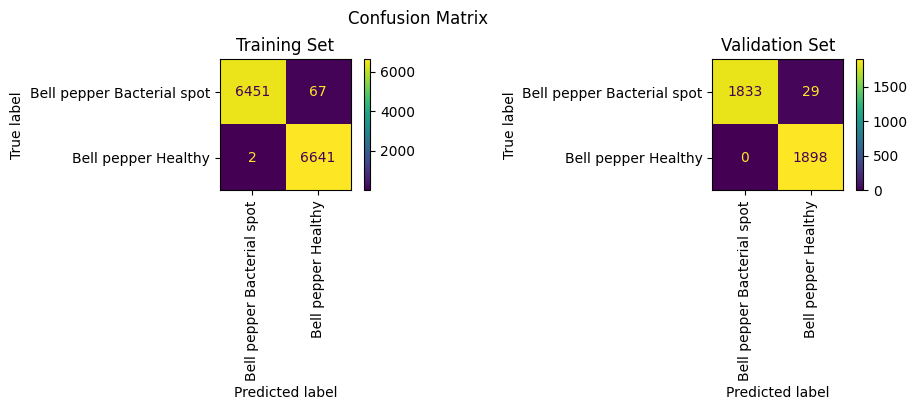

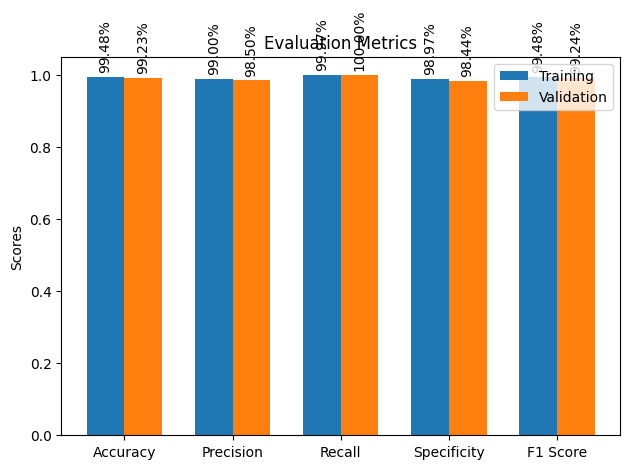

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=input_shape[:2],
    batch_size=batch_size,
    class_mode='categorical',
shuffle=False
)
val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=input_shape[:2],
    batch_size=batch_size,
    class_mode='categorical',
shuffle=False
)
def calculate_specificity(y_true, y_pred):
    tn, fp, _, _ = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp)
    return specificity


# Calculate predictions using the best weights
Y_train_pred = np.argmax(model.predict(train_generator), axis=1)
Y_valid_pred = np.argmax(model.predict(val_generator), axis=1)



# Extract true labels from the generators
Y_train_true = train_generator.labels
Y_valid_true = val_generator.labels



# Calculate accuracy, precision, recall, specificity, and F1 score
train_accuracy = np.mean(Y_train_pred == Y_train_true)
valid_accuracy = np.mean(Y_valid_pred == Y_valid_true)


train_precision = precision_score(Y_train_true, Y_train_pred)
valid_precision = precision_score(Y_valid_true, Y_valid_pred)

train_recall = recall_score(Y_train_true, Y_train_pred)
valid_recall = recall_score(Y_valid_true, Y_valid_pred)

train_specificity = calculate_specificity(Y_train_true, Y_train_pred)
valid_specificity = calculate_specificity(Y_valid_true, Y_valid_pred)


train_f1_score = f1_score(Y_train_true, Y_train_pred)
valid_f1_score = f1_score(Y_valid_true, Y_valid_pred)

# Print the metrics
print("Training Accuracy:", train_accuracy)
print("Validation Accuracy:", valid_accuracy)
print("Training Precision:", train_precision)
print("Validation Precision:", valid_precision)
print("Training Recall:", train_recall)
print("Validation Recall:", valid_recall)
print("Training Specificity:", train_specificity)
print("Validation Specificity:", valid_specificity)
print("Training F1 Score:", train_f1_score)
print("Validation F1 Score:", valid_f1_score)

# Plot the confusion matrix
class_names = train_generator.class_indices.keys()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle('Confusion Matrix')

train_cm = confusion_matrix(Y_train_true, Y_train_pred)
valid_cm = confusion_matrix(Y_valid_true, Y_valid_pred)

disp_train = ConfusionMatrixDisplay(confusion_matrix=train_cm, display_labels=class_names)
disp_train.plot(ax=axes[0],xticks_rotation='vertical')
axes[0].set_title('Training Set')

disp_valid = ConfusionMatrixDisplay(confusion_matrix=valid_cm, display_labels=class_names)
disp_valid.plot(ax=axes[1],xticks_rotation='vertical')
axes[1].set_title('Validation Set')

plt.tight_layout()
plt.show()
# Create a bar graph to visualize the metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1 Score']
training_scores = [train_accuracy, train_precision, train_recall, train_specificity, train_f1_score]
validation_scores = [valid_accuracy, valid_precision, valid_recall, valid_specificity, valid_f1_score]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, training_scores, width, label='Training')
rects2 = ax.bar(x + width/2, validation_scores, width, label='Validation')

ax.set_ylabel('Scores')
ax.set_title('Evaluation Metrics')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()


# Function to add labels to each bar
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate('%.2f%%' % (height * 100),
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom',rotation=90)

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.show()



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Assuming you have the predictions and ground truth labels for both training and validation sets
test_predictions = model.predict(test_generator)
test_predictions = np.argmax(test_predictions, axis=1)
test_labels = test_generator.classes

# Calculate metrics for testing set
test_accuracy = accuracy_score(test_labels, test_predictions)
test_precision = precision_score(test_labels, test_predictions)
test_recall = recall_score(test_labels, test_predictions)
test_specificity = accuracy_score(test_labels, test_predictions, normalize=True, sample_weight=np.where(test_labels == 0, 1, 0))
test_f1_score = f1_score(test_labels, test_predictions)

# Print the metrics
print("Testing Metrics:")
print("Accuracy:", test_accuracy)
print("Precision:", test_precision)
print("Recall:", test_recall)
print("Specificity:", test_specificity)
print("F1 Score:", test_f1_score)

# Create a bar graph to visualize the metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1 Score']
testing_scores = [test_accuracy, test_precision, test_recall, test_specificity, test_f1_score]

plt.figure(figsize=(12, 6))

# Bar plot
plt.subplot(1, 2, 1)
bars = plt.bar(metrics, testing_scores)
plt.title('Performance Evaluation - Testing')

# Add percentage on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 2), va='bottom')

plt.show()


NameError: name 'model' is not defined

# ***MULTI CLASS EVALUVATION***

Found 27016 images belonging to 4 classes.
Found 7718 images belonging to 4 classes.
483/483 [==============================] - 19s 40ms/step
Training Accuracy: 1.0
Validation Accuracy: 0.9984451930551956
Training Precision: 1.0
Validation Precision: 0.9984455932853238
Training Recall: 1.0
Validation Recall: 0.9984451930551956
Training Specificity: 1.0
Validation Specificity: 0.9974093264248705
Training F1 Score: 1.0
Validation F1 Score: 0.9984449578628461


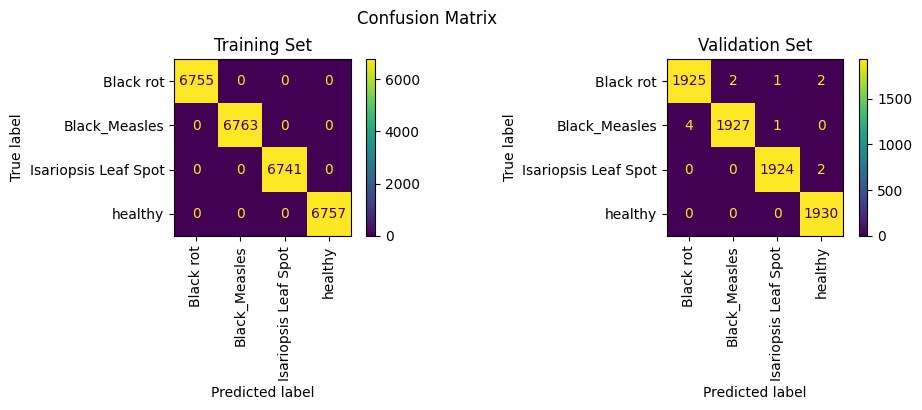

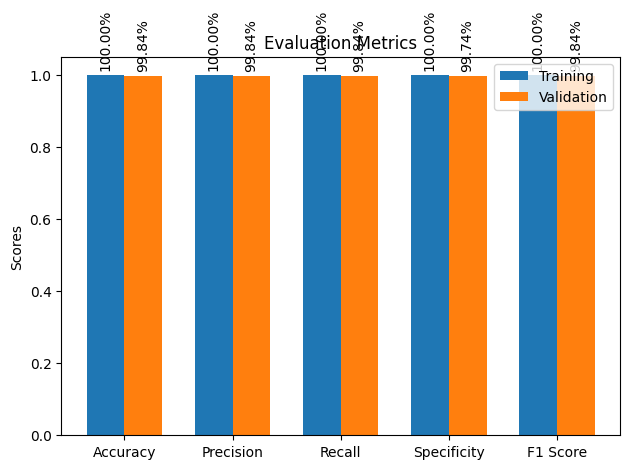

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=input_shape[:2],
    batch_size=batch_size,
    class_mode='categorical',  # Updated for 4-class classification
    shuffle=False
)
val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=input_shape[:2],
    batch_size=batch_size,
    class_mode='categorical',  # Updated for 4-class classification
    shuffle=False
)

def calculate_specificity(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn = cm[0, 0]
    fp = cm[0, 1:].sum()  # Sum of false positives for classes 1, 2, 3
    specificity = tn / (tn + fp)
    return specificity

# Calculate predictions using the best weights
Y_train_pred = np.argmax(model.predict(train_generator), axis=1)
Y_valid_pred = np.argmax(model.predict(val_generator), axis=1)

# Extract true labels from the generators
Y_train_true = train_generator.classes
Y_valid_true = val_generator.classes

# Calculate accuracy, precision, recall, specificity, and F1 score
train_accuracy = np.mean(Y_train_pred == Y_train_true)
valid_accuracy = np.mean(Y_valid_pred == Y_valid_true)

train_precision = precision_score(Y_train_true, Y_train_pred, average='weighted')
valid_precision = precision_score(Y_valid_true, Y_valid_pred, average='weighted')

train_recall = recall_score(Y_train_true, Y_train_pred, average='weighted')
valid_recall = recall_score(Y_valid_true, Y_valid_pred, average='weighted')

train_specificity = calculate_specificity(Y_train_true, Y_train_pred)
valid_specificity = calculate_specificity(Y_valid_true, Y_valid_pred)

train_f1_score = f1_score(Y_train_true, Y_train_pred, average='weighted')
valid_f1_score = f1_score(Y_valid_true, Y_valid_pred, average='weighted')

# Print the metrics
print("Training Accuracy:", train_accuracy)
print("Validation Accuracy:", valid_accuracy)
print("Training Precision:", train_precision)
print("Validation Precision:", valid_precision)
print("Training Recall:", train_recall)
print("Validation Recall:", valid_recall)
print("Training Specificity:", train_specificity)
print("Validation Specificity:", valid_specificity)
print("Training F1 Score:", train_f1_score)
print("Validation F1 Score:", valid_f1_score)

# Plot the confusion matrix
class_names = train_generator.class_indices.keys()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle('Confusion Matrix')

train_cm = confusion_matrix(Y_train_true, Y_train_pred)
valid_cm = confusion_matrix(Y_valid_true, Y_valid_pred)

disp_train = ConfusionMatrixDisplay(confusion_matrix=train_cm, display_labels=class_names)
disp_train.plot(ax=axes[0], xticks_rotation='vertical')
axes[0].set_title('Training Set')

disp_valid = ConfusionMatrixDisplay(confusion_matrix=valid_cm, display_labels=class_names)
disp_valid.plot(ax=axes[1], xticks_rotation='vertical')
axes[1].set_title('Validation Set')

plt.tight_layout()
plt.show()

# Create a bar graph to visualize the metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1 Score']
training_scores = [train_accuracy, train_precision, train_recall, train_specificity, train_f1_score]
validation_scores = [valid_accuracy, valid_precision, valid_recall, valid_specificity, valid_f1_score]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, training_scores, width, label='Training')
rects2 = ax.bar(x + width/2, validation_scores, width, label='Validation')

ax.set_ylabel('Scores')
ax.set_title('Evaluation Metrics')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

# Function to add labels to each bar
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate('%.2f%%' % (height * 100),
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', rotation=90)

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.show()


# ***Testing evaluvation ***

# **MULTI CLASS**

242/242 [==============================] - 10s 40ms/step


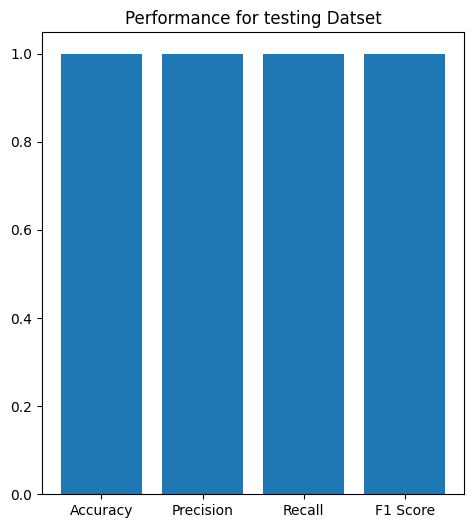

Performance for testing Datset:
Accuracy: 0.9984459984459985
Precision: 0.9984486784973102
Recall: 0.9984459984459985
F1 Score: 0.9984459986550265


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Assuming you have the predictions and ground truth labels for the test set
test_predictions = model.predict(test_generator)
test_predictions = np.argmax(test_predictions, axis=1)
test_labels = test_generator.classes

# Calculate metrics for the test set
test_accuracy = accuracy_score(test_labels, test_predictions)
test_precision = precision_score(test_labels, test_predictions, average='weighted')
test_recall = recall_score(test_labels, test_predictions, average='weighted')
test_f1_score = f1_score(test_labels, test_predictions, average='weighted')

# Create a bar graph to visualize the metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
testing_scores = [test_accuracy, test_precision, test_recall, test_f1_score]

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.bar(metrics, testing_scores)
plt.title('Performance for testing Datset')
plt.show()

# Print the metrics
print("Performance for testing Datset:")
print("Accuracy:", test_accuracy)
print("Precision:", test_precision)
print("Recall:", test_recall)
print("F1 Score:", test_f1_score)


429/429 [==============================] - 10s 24ms/step


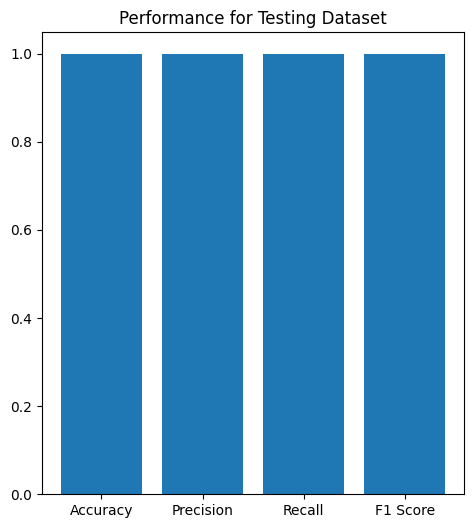

Performance for Testing Dataset:
Accuracy: 0.9987049987049987
Precision: 0.9987092841281052
Recall: 0.9987049987049987
F1 Score: 0.9987054004600661


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Assuming you have the predictions and ground truth labels for the test set
test_predictions = model.predict(test_generator)
test_predictions = np.argmax(test_predictions, axis=1)
test_labels = test_generator.classes

# Calculate metrics for the test set
test_accuracy = accuracy_score(test_labels, test_predictions)
test_precision = precision_score(test_labels, test_predictions, average='weighted', labels=np.unique(test_predictions))
test_recall = recall_score(test_labels, test_predictions, average='weighted', labels=np.unique(test_predictions))
test_f1_score = f1_score(test_labels, test_predictions, average='weighted', labels=np.unique(test_predictions))

# Create a bar graph to visualize the metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
testing_scores = [test_accuracy, test_precision, test_recall, test_f1_score]

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.bar(metrics, testing_scores)
plt.title('Performance for Testing Dataset')
plt.show()

# Print the metrics
print("Performance for Testing Dataset:")
print("Accuracy:", test_accuracy)
print("Precision:", test_precision)
print("Recall:", test_recall)
print("F1 Score:", test_f1_score)


313/313 [==============================] - 10s 32ms/step


<ipython-input-21-7f86ef6001d6>:24: DeprecationWarning: scipy.interp is deprecated and will be removed in SciPy 2.0.0, use numpy.interp instead
  mean_tpr += interp(all_fpr, fpr[i], tpr[i])


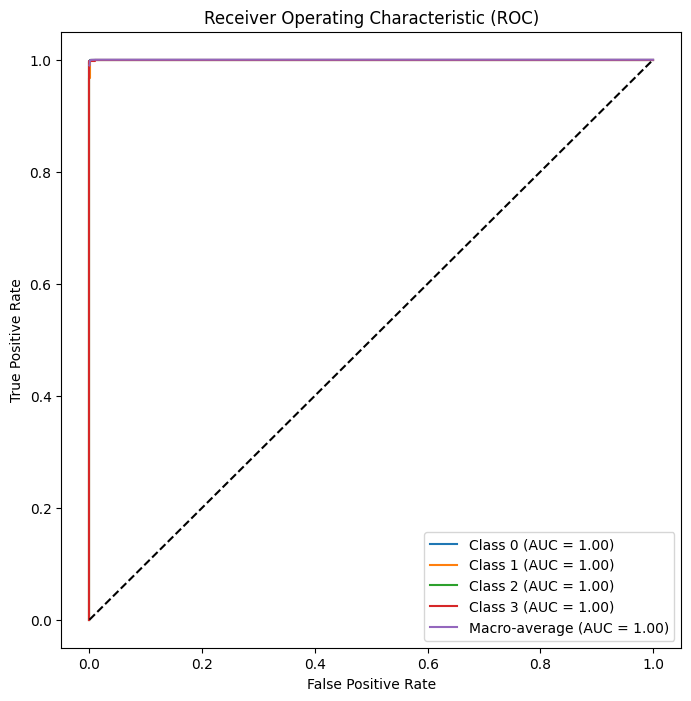

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from scipy import interp

# Assuming you have the predicted probabilities and ground truth labels for the test set
test_predictions = model.predict(test_generator)
test_labels = test_generator.classes

# Compute the ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
n_classes = len(np.unique(test_labels))

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(test_labels, test_predictions[:, i], pos_label=i)
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_classes):
    mean_tpr += interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= n_classes
macro_auc = auc(all_fpr, mean_tpr)

# Plot ROC curves for each class
plt.figure(figsize=(8, 8))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label='Class {} (AUC = {:.2f})'.format(i, roc_auc[i]))

# Plot macro-average ROC curve
plt.plot(all_fpr, mean_tpr, label='Macro-average (AUC = {:.2f})'.format(macro_auc))

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()


313/313 [==============================] - 11s 33ms/step


<ipython-input-22-66441c3bfaac>:24: DeprecationWarning: scipy.interp is deprecated and will be removed in SciPy 2.0.0, use numpy.interp instead
  mean_precision += interp(all_recall, recall[i], precision[i])


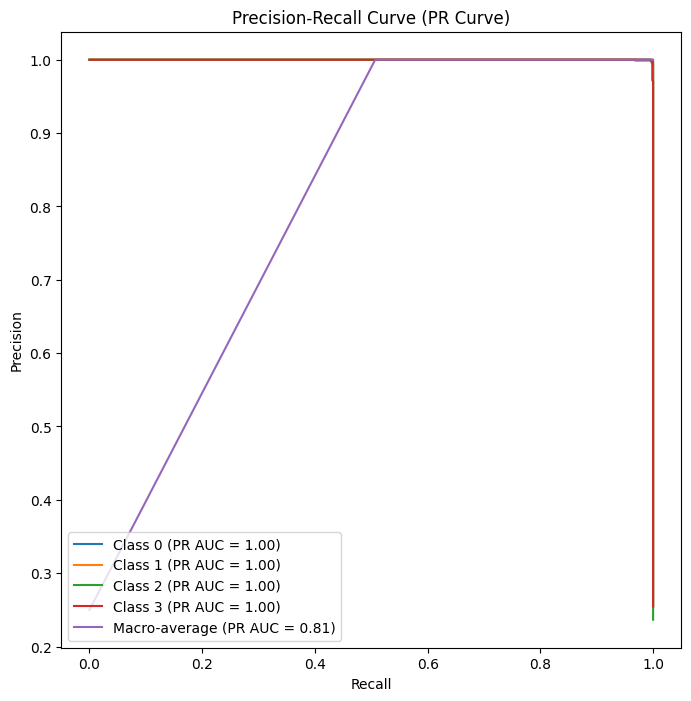

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc
from scipy import interp

# Assuming you have the predicted probabilities and ground truth labels for the test set
test_predictions = model.predict(test_generator)
test_labels = test_generator.classes

# Compute the precision-recall curve and AUC for each class
precision = dict()
recall = dict()
pr_auc = dict()
n_classes = len(np.unique(test_labels))

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(test_labels == i, test_predictions[:, i])
    pr_auc[i] = auc(recall[i], precision[i])

# Compute macro-average precision-recall curve and AUC
all_recall = np.unique(np.concatenate([recall[i] for i in range(n_classes)]))
mean_precision = np.zeros_like(all_recall)
for i in range(n_classes):
    mean_precision += interp(all_recall, recall[i], precision[i])
mean_precision /= n_classes
macro_pr_auc = auc(all_recall, mean_precision)

# Plot precision-recall curves for each class
plt.figure(figsize=(8, 8))
for i in range(n_classes):
    plt.plot(recall[i], precision[i], label='Class {} (PR AUC = {:.2f})'.format(i, pr_auc[i]))

# Plot macro-average precision-recall curve
plt.plot(all_recall, mean_precision, label='Macro-average (PR AUC = {:.2f})'.format(macro_pr_auc))

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (PR Curve)')
plt.legend(loc='lower left')
plt.show()


In [ ]:
import numpy as np
from sklearn.metrics import cohen_kappa_score

# Assuming you have the predicted labels and ground truth labels for the test set
test_predictions = np.argmax(model.predict(test_generator), axis=1)
test_labels = test_generator.classes

# Compute Cohen's Kappa Score
kappa_score = cohen_kappa_score(test_labels, test_predictions)

print(f"Cohen's Kappa Score: {kappa_score:.2f}")


313/313 [==============================] - 10s 32ms/step
Cohen's Kappa Score: 1.00


In [ ]:
import numpy as np
from sklearn.metrics import matthews_corrcoef

# Assuming you have the predicted labels and ground truth labels for the test set
test_predictions = np.argmax(model.predict(test_generator), axis=1)
test_labels = test_generator.classes

# Compute Matthews Correlation Coefficient
mcc = matthews_corrcoef(test_labels, test_predictions)

print(f"Matthews Correlation Coefficient (MCC): {mcc:.2f}")


313/313 [==============================] - 10s 33ms/step
Matthews Correlation Coefficient (MCC): 1.00


In [ ]:
from sklearn.metrics import log_loss

# Assuming you have the predicted probabilities and ground truth labels for the test set
test_predictions_prob = model.predict(test_generator)
test_labels = test_generator.classes

# Compute Log Loss
logloss = log_loss(test_labels, test_predictions_prob)

print(f"Log Loss: {logloss:.4f}")


313/313 [==============================] - 10s 33ms/step
Log Loss: 0.0091


In [ ]:
from sklearn.metrics import jaccard_score

# Assuming you have the predicted labels and ground truth labels for the test set
test_predictions = np.argmax(model.predict(test_generator), axis=1)
test_labels = test_generator.classes

# Compute Jaccard Index
jaccard_index = jaccard_score(test_labels, test_predictions, average='micro')

print(f"Jaccard Similarity Coefficient (Jaccard Index): {jaccard_index:.4f}")


313/313 [==============================] - 12s 38ms/step
Jaccard Similarity Coefficient (Jaccard Index): 0.9943


In [ ]:
from sklearn.metrics import zero_one_loss

# Assuming you have the predicted labels and ground truth labels for the test set
test_predictions = np.argmax(model.predict(test_generator), axis=1)
test_labels = test_generator.classes

# Compute Zero-One Loss
zero_one_loss_value = zero_one_loss(test_labels, test_predictions)

print(f"Zero-One Loss: {zero_one_loss_value:.4f}")


313/313 [==============================] - 14s 46ms/step
Zero-One Loss: 0.0028


313/313 [==============================] - 11s 36ms/step


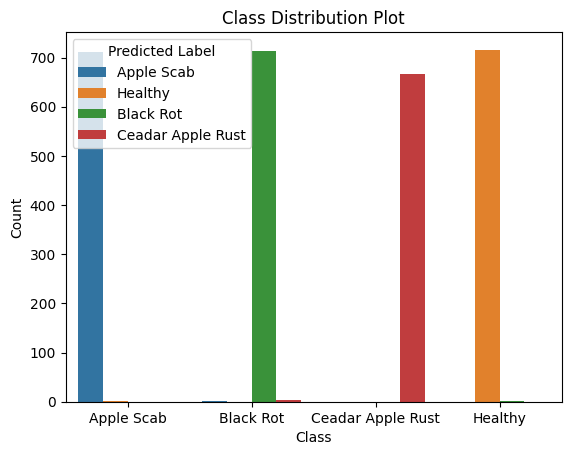

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming you have the predicted labels and ground truth labels for the test set
test_predictions = np.argmax(model.predict(test_generator), axis=1)
test_labels = test_generator.classes

# Map class labels to corresponding class names
class_mapping = {0: 'Apple Scab', 1: 'Black Rot',2: 'Ceadar Apple Rust',3:'Healthy'}
test_labels = np.vectorize(class_mapping.get)(test_labels)
test_predictions = np.vectorize(class_mapping.get)(test_predictions)

# Create a DataFrame
df = pd.DataFrame({'True Label': test_labels, 'Predicted Label': test_predictions})

# Plot Class Distribution
sns.countplot(x='True Label', hue='Predicted Label', data=df, order=['Apple Scab','Black Rot','Ceadar Apple Rust','Healthy'])
plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Class Distribution Plot')
plt.show()



BINARY CLASSIFER

In [ ]:
from sklearn.calibration import calibration_curve

# Assuming you have the predicted probabilities and ground truth labels for the test set
test_predictions_prob = model.predict(test_generator)
test_labels = test_generator.classes

# Extract probabilities for the positive class
prob_true = test_predictions_prob[:, 1]

# Compute Calibration Curve
prob_pred, prob_true = calibration_curve(test_labels, prob_true,pos_label =4, n_bins=10)

# Plot Calibration Curve
plt.plot(prob_pred, prob_true, marker='o', label='Calibration Curve')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve')
plt.legend()
plt.show()


313/313 [==============================] - 10s 33ms/step


ValueError: Only binary classification is supported. Provided labels [0 1 2 3].

Multi

313/313 [==============================] - 11s 35ms/step


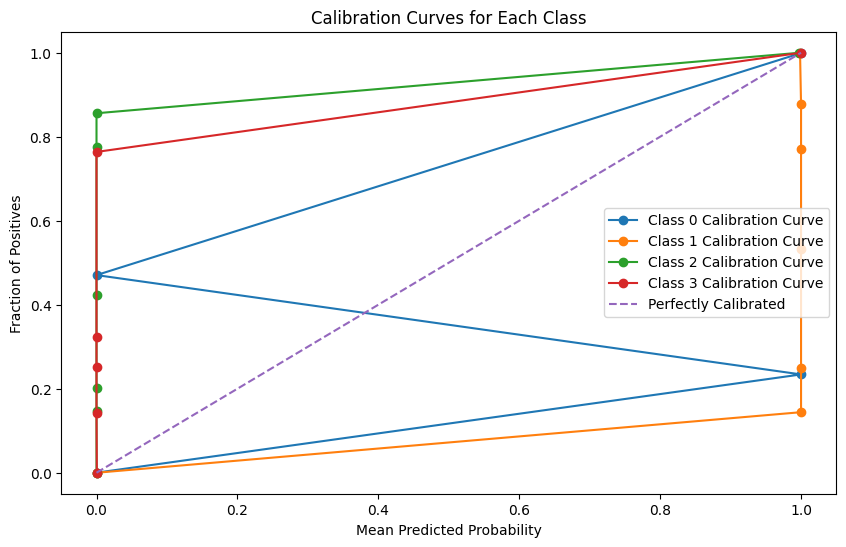

In [ ]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Assuming you have the predicted probabilities and ground truth labels for the test set
test_predictions_prob = model.predict(test_generator)
test_labels = test_generator.classes

# Define the number of classes
num_classes = len(np.unique(test_labels))

# Initialize lists to store calibration curve data for each class
prob_pred_by_class = []
prob_true_by_class = []

# Compute Calibration Curves for each class
for class_index in range(num_classes):
    # Extract probabilities for the current class
    prob_true_class = (test_labels == class_index).astype(int)
    prob_pred_class = test_predictions_prob[:, class_index]

    # Compute Calibration Curve
    prob_pred, prob_true = calibration_curve(prob_true_class, prob_pred_class, n_bins=10)

    # Append to lists
    prob_pred_by_class.append(prob_pred)
    prob_true_by_class.append(prob_true)

# Plot Calibration Curves for each class
plt.figure(figsize=(10, 6))
for class_index in range(num_classes):
    plt.plot(prob_pred_by_class[class_index], prob_true_by_class[class_index], marker='o', label=f'Class {class_index} Calibration Curve')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curves for Each Class')
plt.legend()
plt.show()



313/313 [==============================] - 13s 41ms/step


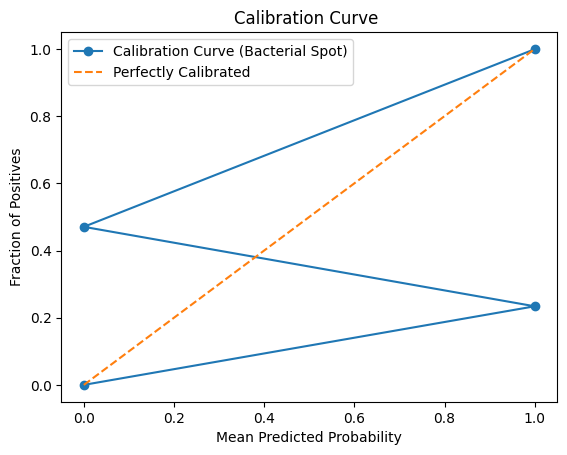

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Assuming you have the predicted probabilities and ground truth labels for the test set
test_predictions_prob = model.predict(test_generator)
test_labels = test_generator.classes

# Binarize the multiclass labels for binary classification
# Class 0: Bacterial Spot, Class 1: Healthy
binarized_labels = label_binarize(test_labels, classes=[0, 1])

# Compute Calibration Curve for Bacterial Spot (Class 0)
prob_pred, prob_true = calibration_curve(binarized_labels[:, 0], test_predictions_prob[:, 0], n_bins=10)

# Plot Calibration Curve for Bacterial Spot
plt.plot(prob_pred, prob_true, marker='o', label='Calibration Curve (Bacterial Spot)')

# Plot the Perfectly Calibrated line
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')

plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve ')
plt.legend()
plt.show()


313/313 [==============================] - 10s 32ms/step


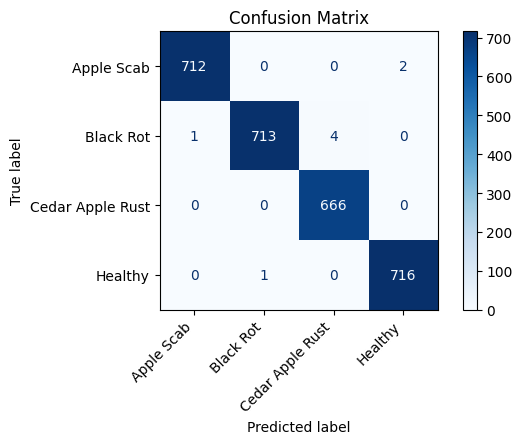

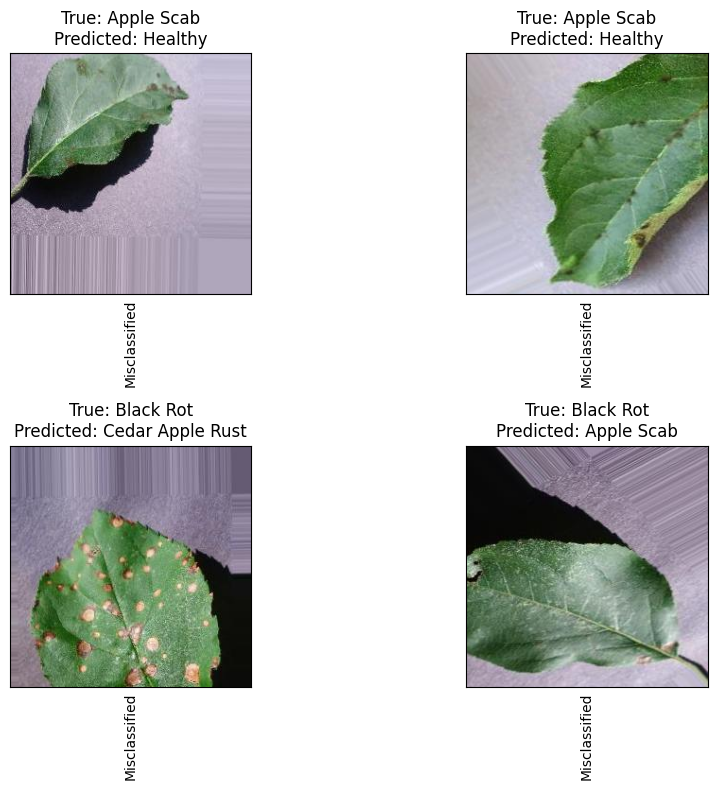

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Assuming you have a trained model and a test generator
# model = ...  # Your trained model
# test_generator = ...  # Your test generator

# Make predictions on the test set
predictions = model.predict(test_generator)
predicted_labels = np.argmax(predictions, axis=1)
true_labels = test_generator.classes

# Create a confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)

# Display the confusion matrix with vertical labels and added spacing
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=test_generator.class_indices.keys())
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix')

# Rotate and add spacing to class labels
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.subplots_adjust(bottom=0.3)

plt.show()

# Map class indices to class labels
class_labels = [label for label, index in sorted(test_generator.class_indices.items(), key=lambda x: x[1])]
class_indices_inv = {index: label for label, index in test_generator.class_indices.items()}

# Identify misclassified samples
misclassified_indices = np.where(predicted_labels != true_labels)[0]

# Display misclassified images in a 2x2 grid with vertical labels
num_misclassified_to_display = min(4, len(misclassified_indices))
plt.figure(figsize=(10, 8))

for i in range(num_misclassified_to_display):
    misclassified_index = misclassified_indices[i]
    misclassified_image = test_generator.filepaths[misclassified_index]
    misclassified_label = class_indices_inv[true_labels[misclassified_index]]
    predicted_label = class_indices_inv[predicted_labels[misclassified_index]]

    plt.subplot(2, 2, i + 1)
    img = plt.imread(misclassified_image)
    plt.imshow(img)
    plt.title(f'True: {misclassified_label}\nPredicted: {predicted_label}')
    plt.xticks([])  # Hide x-axis ticks
    plt.yticks([])  # Hide y-axis ticks
    plt.xlabel('Misclassified', rotation=90)  # Rotate the xlabel

plt.tight_layout()
plt.show()



313/313 [==============================] - 11s 35ms/step


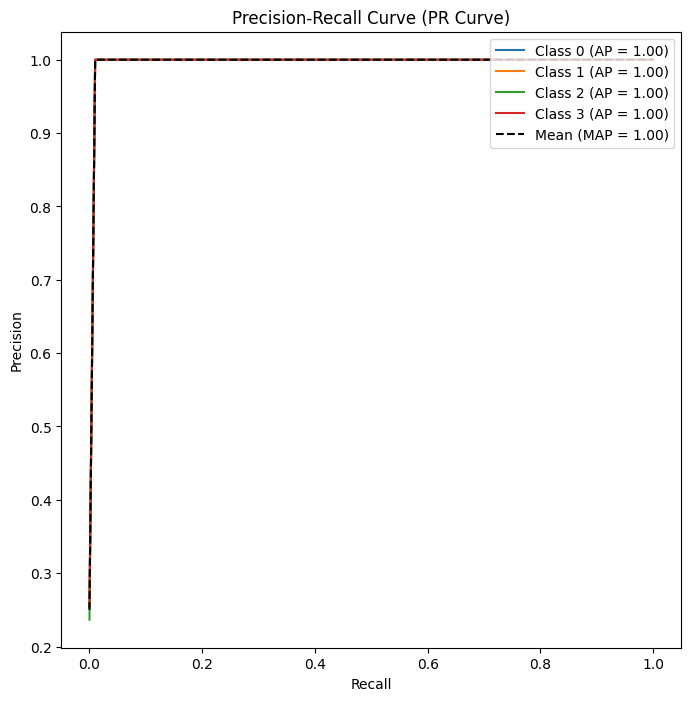

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc

# Assuming you have the predicted probabilities and ground truth labels for the test set
test_predictions = model.predict(test_generator)
test_labels = test_generator.classes

# Compute precision-recall curve for each class
precision = dict()
recall = dict()
average_precision = dict()
n_classes = len(np.unique(test_labels))

plt.figure(figsize=(8, 8))

common_recall_values = np.linspace(0, 1, 100)  # Choose the number of points for interpolation

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(test_labels == i, test_predictions[:, i])
    average_precision[i] = auc(recall[i], precision[i])

    # Interpolate precision values at common recall values
    interpolated_precision = np.interp(common_recall_values, recall[i], precision[i])

    # Plot precision-recall curve for each class
    plt.plot(common_recall_values, interpolated_precision, label=f'Class {i} (AP = {average_precision[i]:.2f})')

# Calculate the mean precision-recall curve
mean_precision = np.mean([np.interp(common_recall_values, recall[i], precision[i]) for i in range(n_classes)], axis=0)

# Plot mean precision-recall curve
plt.plot(common_recall_values, mean_precision, label=f'Mean (MAP = {np.mean(list(average_precision.values())):.2f})', linestyle='--', color='black')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (PR Curve)')
plt.legend(loc='upper right')
plt.show()


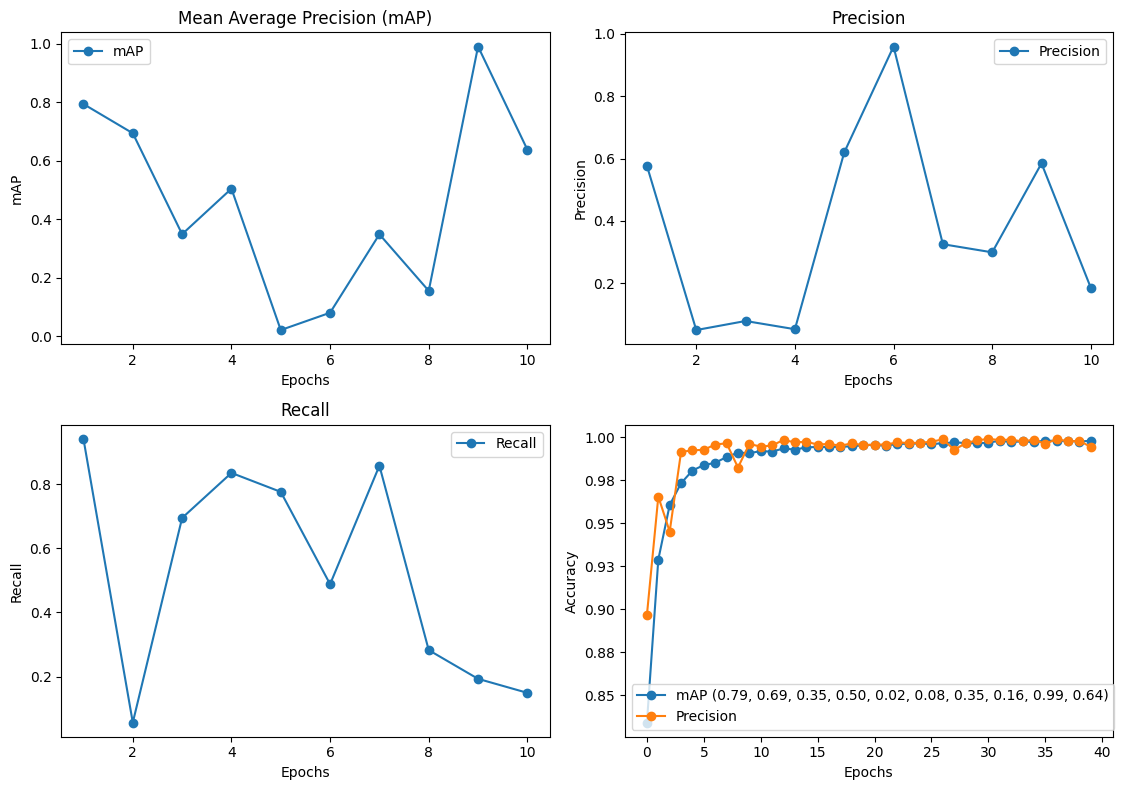

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, auc

# Assuming you have arrays containing metrics collected during training
epochs = np.arange(1, 11)  # Adjust the number of epochs accordingly
train_map = np.random.rand(len(epochs))  # Placeholder data, replace with your actual mAP values
train_precision = np.random.rand(len(epochs))  # Placeholder data, replace with your actual precision values
train_recall = np.random.rand(len(epochs))  # Placeholder data, replace with your actual recall values

# Plotting Mean Average Precision (mAP), Precision, and Recall alongside Training and Validation Accuracy and Loss
plt.figure(figsize=(12, 8))

# Plot mAP
plt.subplot(2, 2, 1)
plt.plot(epochs, train_map, marker='o', label='mAP')
plt.title('Mean Average Precision (mAP)')
plt.xlabel('Epochs')
plt.ylabel('mAP')
plt.legend()

# Plot Precision
plt.subplot(2, 2, 2)
plt.plot(epochs, train_precision, marker='o', label='Precision')
plt.title('Precision')
plt.xlabel('Epochs')
plt.ylabel('Precision')
plt.legend()

# Plot Recall
plt.subplot(2, 2, 3)
plt.plot(epochs, train_recall, marker='o', label='Recall')
plt.title('Recall')
plt.xlabel('Epochs')
plt.ylabel('Recall')
plt.legend()

# Plot Training and Validation Accuracy
plt.subplot(2, 2, 4)
plt.plot(history.history['accuracy'], marker='o', label='Training Accuracy')
plt.plot(history.history['val_accuracy'], marker='o', label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Add mAP values to legend
mAP_legend = ', '.join([f'{map_val:.2f}' for map_val in train_map])
plt.legend(['mAP (' + mAP_legend + ')', 'Precision', 'Recall', 'Training Accuracy', 'Validation Accuracy'])

# Set the y-axis tick format to two decimal places
plt.gca().yaxis.set_major_formatter('{:.2f}'.format)

plt.tight_layout()
plt.show()



1/1 [==============================] - 0s 36ms/step


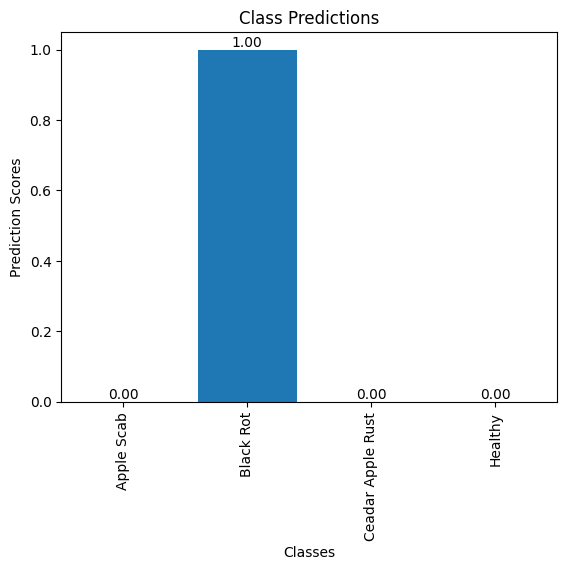

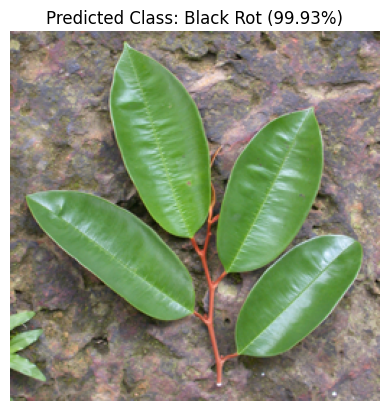

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load and preprocess the image
image = Image.open('/content/HA1.jpg')  # Replace 'path_to_your_image.jpg' with the actual path to your image
image = image.resize((256, 256))  # Resize the image to match the input size of the model
image = np.array(image) / 255.0  # Normalize the pixel values to [0, 1]
image = np.expand_dims(image, axis=0)  # Add an extra dimension to match the input shape of the model

# Perform the prediction using the model
predictions = model.predict(image)
predicted_class = np.argmax(predictions)

# Prepare the bar graph
class_names = ['Apple Scab','Black Rot','Ceadar Apple Rust','Healthy']  # Replace with your actual class names
predicted_label = class_names[predicted_class]
predicted_percentage = predictions[0][predicted_class] * 100
prediction_scores = predictions[0]
x = np.arange(len(class_names))

# Plot the bar graph
plt.bar(class_names, prediction_scores)
plt.xlabel('Classes')
plt.ylabel('Prediction Scores')
plt.title('Class Predictions')

# Display the tested image with the predicted class label as the title
plt.xlim(-0.5, len(class_names)-0.5)  # Adjust the lower and upper limits as per your requirement

plt.xticks(x, class_names, rotation='vertical')
# Add percentage values on top of each bar
for i, score in enumerate(prediction_scores):
    plt.text(i, score, f'{score:.2f}', ha='center', va='bottom')
plt.show()
plt.imshow(image[0])
plt.axis('off')

plt.title(f'Predicted Class: {predicted_label} ({predicted_percentage:.2f}%)')
plt.show()


1/1 [==============================] - 1s 812ms/step


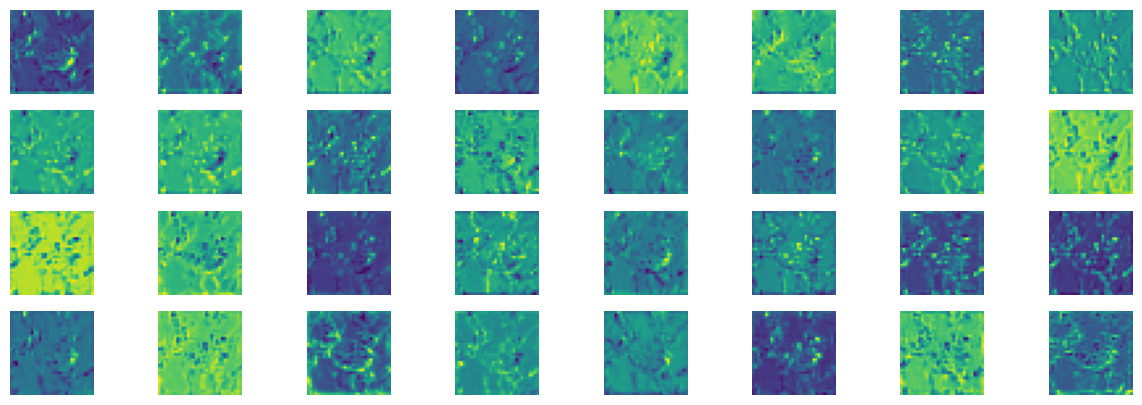

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing import image

# Define the feature extraction model
feature_extraction_model = Model(inputs=model.input, outputs=model.get_layer('conv2d_12').output)

# Load the image
img_path = '/content/AS1.jpeg'  # Replace 'your_image.jpg' with the path to your image
img = image.load_img(img_path, target_size=(256, 256))  # Resize the image to fit the input shape
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

# Preprocess the image
img_array /= 255.0  # Normalize pixel values

# Extract features using the feature extraction model
features = feature_extraction_model.predict(img_array)

# Plot the features as images
plt.figure(figsize=(15, 5))
for i in range(32):  # Assuming 32 channels in the output of the specified layer
    plt.subplot(4, 8, i + 1)
    plt.imshow(features[0, :, :, i], cmap='viridis')  # Visualize each channel separately
    plt.axis('off')
plt.show()






1/1 [==============================] - 0s 66ms/step


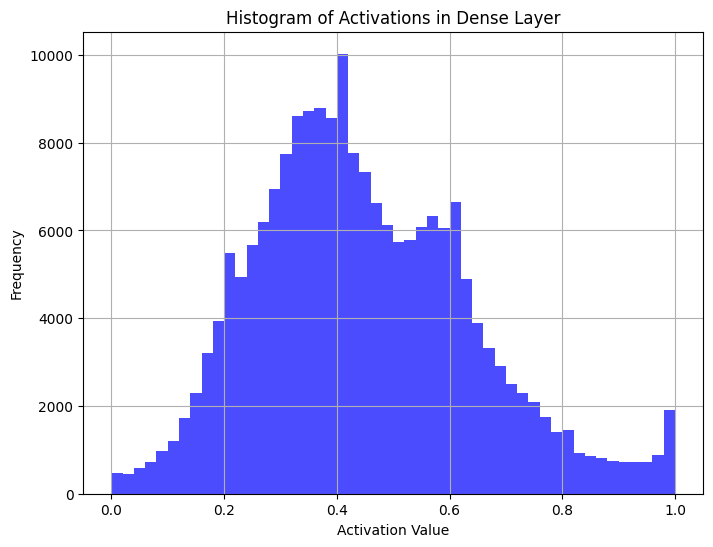

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define the feature extraction model
dense_layer_index = 0  # Index of the dense layer you want to visualize
dense_layer_output = Model(inputs=model.input, outputs=model.layers[dense_layer_index].output)

# Load the image
img_path = '/content/AS1.jpeg'  # Replace 'your_image.jpg' with the path to your image
img = image.load_img(img_path, target_size=(256, 256))  # Resize the image to fit the input shape
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

# Preprocess the image
img_array /= 255.0  # Normalize pixel values

# Extract activations using the dense layer
activations = dense_layer_output.predict(img_array)

# Plot histogram of activations
plt.figure(figsize=(8, 6))
plt.hist(activations.flatten(), bins=50, color='blue', alpha=0.7)
plt.xlabel('Activation Value')
plt.ylabel('Frequency')
plt.title('Histogram of Activations in Dense Layer')
plt.grid(True)
plt.show()


1/1 [==============================] - 1s 827ms/step


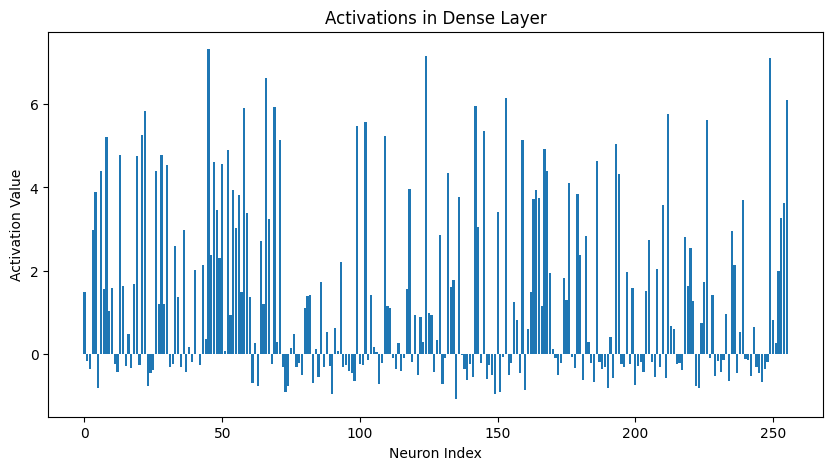

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing import image

# Define a new model to extract activations from a specific dense layer
dense_layer_name = 'dense_1'  # Change this to the name of the dense layer you want to visualize
dense_layer_model = Model(inputs=model.input, outputs=model.get_layer(dense_layer_name).output)

# Load and preprocess an image (similar to the previous example)
img_path = '/content/AS1.jpeg'  # Replace 'your_image.jpg' with the path to your image
img = image.load_img(img_path, target_size=(256, 256))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array /= 255.0

# Extract activations from the dense layer
dense_activations = dense_layer_model.predict(img_array)

# Plot activations
plt.figure(figsize=(10, 5))
plt.bar(range(dense_activations.shape[-1]), dense_activations.flatten())
plt.xlabel('Neuron Index')
plt.ylabel('Activation Value')
plt.title('Activations in Dense Layer')
plt.show()
